# TP4 : Architecture Transformer

## 1. Génération du dataset
Série temporelle `s = sin(x)` : 200 valeurs entre 0 et 20, rangées en séquences de dimension 10. Chaque séquence `X` prédit la valeur suivante `Y`.

In [28]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# 200 valeurs de sin(x) entre 0 et 20
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)

# Séquences de dimension 10 : X = [s0..s9], [s1..s10], ... ; Y = [s10], [s11], ...
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme attendue par les modèles : (nombre de séquences, longueur, 1)
X = X.unsqueeze(-1)
y = y.unsqueeze(-1)

# Découpage chronologique : début pour apprendre, fin pour tester
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

print("X :", X.shape)
print("y :", y.shape)
print("X_train :", X_train.shape, "| X_test :", X_test.shape)
print("Premier exemple X :", X[0].squeeze().tolist())
print("Premier exemple Y :", y[0].item())

X : torch.Size([190, 10, 1])
y : torch.Size([190, 1])
X_train : torch.Size([150, 10, 1]) | X_test : torch.Size([40, 10, 1])
Premier exemple X : [0.0, 0.10033340752124786, 0.199654221534729, 0.29696008563041687, 0.39126893877983093, 0.48162901401519775, 0.5671283602714539, 0.6469041109085083, 0.7201511263847351, 0.7861301898956299]
Premier exemple Y : 0.8441754579544067


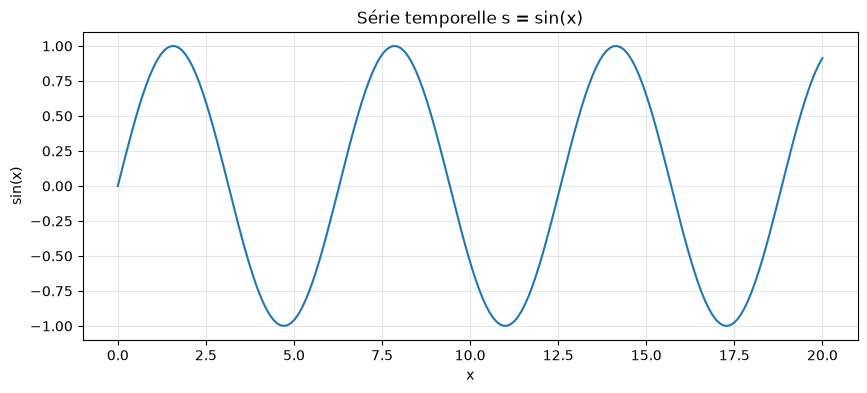

In [29]:
plt.figure(figsize=(10, 4))
plt.plot(periode, serie)
plt.title("Série temporelle s = sin(x)")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.grid(True, alpha=0.3)
plt.show()

## 2. Modèle RNN
Architecture : RNN (16 unités) qui lit la séquence de 10 valeurs, puis une couche Linear 16 → 1 appliquée au dernier état caché pour prédire la valeur suivante.

In [30]:
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=16, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.rnn(x)          # (batch, 10, 16)
        dernier_etat = etats[:, -1, :]  # (batch, 16)
        return self.sortie(dernier_etat)  # (batch, 1)


modele_rnn = SimpleRNN()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_rnn.parameters(), lr=0.01)

print(modele_rnn)

SimpleRNN(
  (rnn): RNN(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)


In [31]:
# Entraînement
modele_rnn.train()
for epoch in range(300):
    predictions = modele_rnn(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")

# Test
modele_rnn.eval()
with torch.no_grad():
    predictions_rnn = modele_rnn(X_test)
    erreur_test_rnn = critere(predictions_rnn, y_test)

print(f"\nErreur de test : {erreur_test_rnn.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions_rnn[0].item():.4f}")

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025

Erreur de test : 0.000028
Valeur réelle  : -0.3639
Valeur prédite : -0.3601


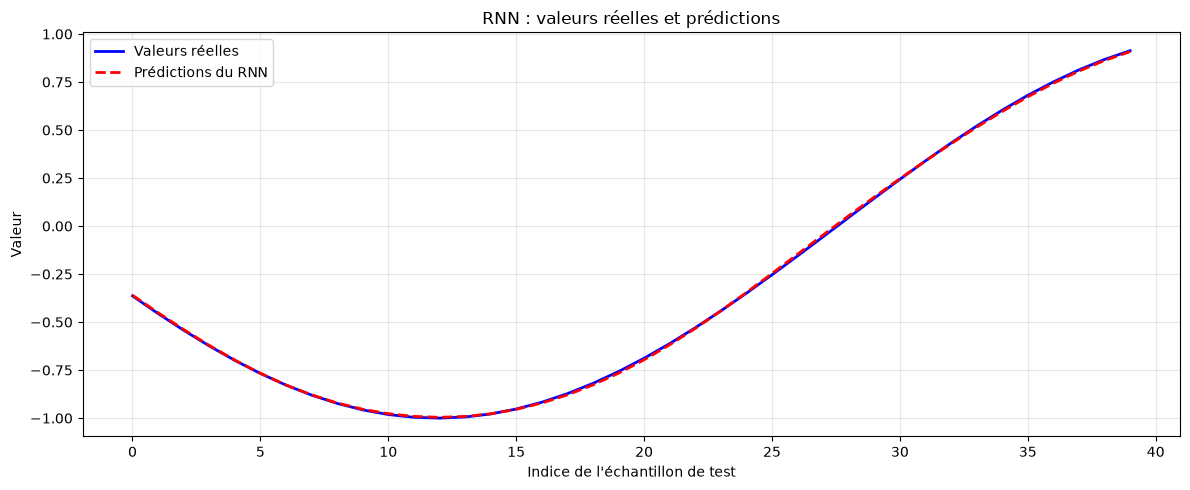

In [32]:
valeurs_reelles = y_test.detach().numpy().reshape(-1)
valeurs_predites = predictions_rnn.detach().numpy().reshape(-1)

plt.figure(figsize=(12, 5))
plt.plot(valeurs_reelles, label="Valeurs réelles", color="blue", linewidth=2)
plt.plot(valeurs_predites, label="Prédictions du RNN", color="red", linestyle="--", linewidth=2)
plt.title("RNN : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Modèle LSTM
Même architecture que le RNN, mais avec une cellule LSTM (16 unités) qui garde en plus un état de cellule `c`. Une couche Linear 16 → 1 est appliquée au dernier état caché `h`.

In [33]:
class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=16, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, (h_n, c_n) = self.lstm(x)  # etats : (batch, 10, 16)
        dernier_etat = etats[:, -1, :]    # (batch, 16)
        return self.sortie(dernier_etat)  # (batch, 1)


torch.manual_seed(42)
modele_lstm = SimpleLSTM()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_lstm.parameters(), lr=0.01)

print(modele_lstm)

SimpleLSTM(
  (lstm): LSTM(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)


In [34]:
# Entraînement
modele_lstm.train()
for epoch in range(300):
    predictions = modele_lstm(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")

# Test
modele_lstm.eval()
with torch.no_grad():
    predictions_lstm = modele_lstm(X_test)
    erreur_test_lstm = critere(predictions_lstm, y_test)

print(f"\nErreur de test : {erreur_test_lstm.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions_lstm[0].item():.4f}")

Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248
Epoch 150 | Erreur : 0.000043
Epoch 200 | Erreur : 0.000006
Epoch 250 | Erreur : 0.000004
Epoch 300 | Erreur : 0.000003

Erreur de test : 0.000003
Valeur réelle  : -0.3639
Valeur prédite : -0.3622


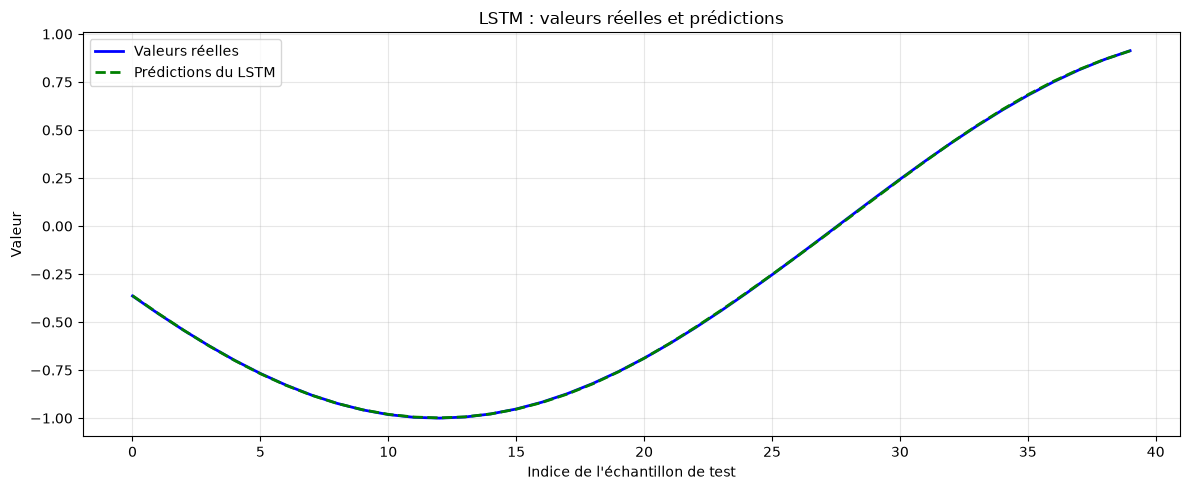

Erreur de test RNN  : 0.000028
Erreur de test LSTM : 0.000003


In [35]:
valeurs_reelles = y_test.detach().numpy().reshape(-1)
valeurs_predites = predictions_lstm.detach().numpy().reshape(-1)

plt.figure(figsize=(12, 5))
plt.plot(valeurs_reelles, label="Valeurs réelles", color="blue", linewidth=2)
plt.plot(valeurs_predites, label="Prédictions du LSTM", color="green", linestyle="--", linewidth=2)
plt.title("LSTM : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Erreur de test RNN  : {erreur_test_rnn.item():.6f}")
print(f"Erreur de test LSTM : {erreur_test_lstm.item():.6f}")

## 4. Modèle Transformer
Architecture demandée :
1. Projection linéaire 1 → 16 de chaque valeur de la séquence.
2. Positional embedding (indices 0, 1, ..., n-1) additionné à la projection.
3. Multi-Head Self-Attention (2 têtes, dimension 16), puis connexion résiduelle + LayerNorm.
4. Feed-Forward 16 → 32 → 16 avec ReLU, puis connexion résiduelle + LayerNorm.
5. On garde la dernière représentation de la séquence, puis Linear 16 → 1.

In [36]:
class SimpleTransformer(nn.Module):
    def __init__(self, longueur_sequence=10, dim=16, nb_tetes=2):
        super().__init__()

        # 1. Projection linéaire 1 -> 16
        self.projection = nn.Linear(1, dim)

        # 2. Positional embedding : un vecteur de 16 nombres par position
        self.position = nn.Embedding(longueur_sequence, dim)

        # 3. Multi-Head Self-Attention (2 têtes, dimension 16)
        self.attention = nn.MultiheadAttention(
            embed_dim=dim, num_heads=nb_tetes, batch_first=True
        )
        self.norm1 = nn.LayerNorm(dim)

        # 4. Feed-Forward 16 -> 32 -> 16 avec ReLU
        self.feed_forward = nn.Sequential(
            nn.Linear(dim, 32),
            nn.ReLU(),
            nn.Linear(32, dim),
        )
        self.norm2 = nn.LayerNorm(dim)

        # 5. Sortie : 16 -> 1
        self.sortie = nn.Linear(dim, 1)

    def forward(self, x):
        # x : (batch, 10, 1)
        n = x.shape[1]
        indices = torch.arange(n, device=x.device)       # 0, 1, ..., n-1

        h = self.projection(x) + self.position(indices)  # (batch, 10, 16)

        # Self-attention + résiduel + norm
        sortie_attention, _ = self.attention(h, h, h)
        h = self.norm1(h + sortie_attention)

        # Feed-forward + résiduel + norm
        h = self.norm2(h + self.feed_forward(h))

        # On garde la dernière représentation
        derniere = h[:, -1, :]                           # (batch, 16)
        return self.sortie(derniere)                     # (batch, 1)


torch.manual_seed(42)
modele_transformer = SimpleTransformer()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_transformer.parameters(), lr=0.01)

print(modele_transformer)

SimpleTransformer(
  (projection): Linear(in_features=1, out_features=16, bias=True)
  (position): Embedding(10, 16)
  (attention): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
  )
  (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
  (feed_forward): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
  )
  (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)


In [37]:
# Entraînement
modele_transformer.train()
for epoch in range(300):
    predictions = modele_transformer(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")

# Test
modele_transformer.eval()
with torch.no_grad():
    predictions_transformer = modele_transformer(X_test)
    erreur_test_transformer = critere(predictions_transformer, y_test)

print(f"\nErreur de test : {erreur_test_transformer.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions_transformer[0].item():.4f}")

Epoch  50 | Erreur : 0.001504
Epoch 100 | Erreur : 0.000110
Epoch 150 | Erreur : 0.000026
Epoch 200 | Erreur : 0.000012
Epoch 250 | Erreur : 0.000007
Epoch 300 | Erreur : 0.000004

Erreur de test : 0.000006
Valeur réelle  : -0.3639
Valeur prédite : -0.3662


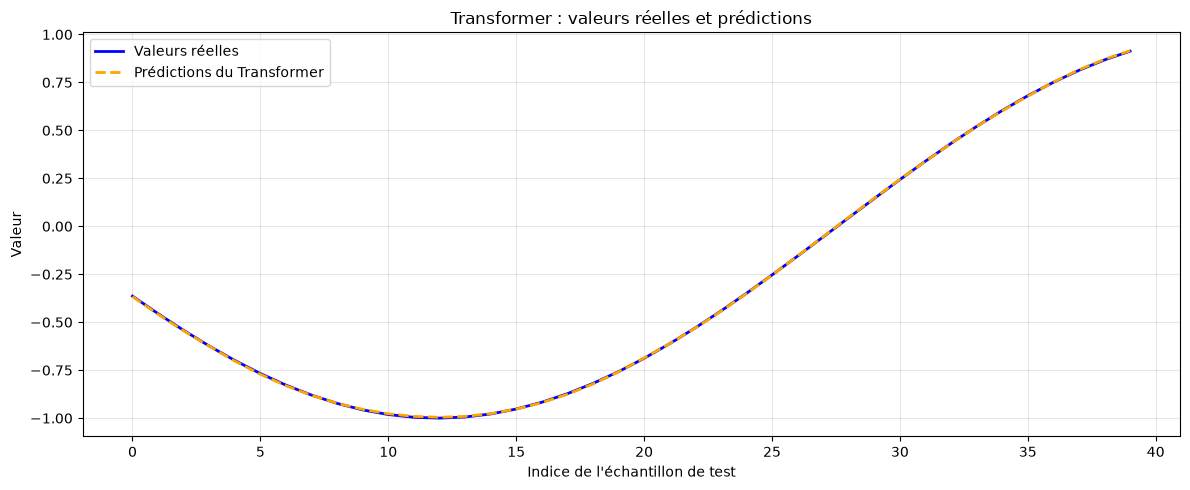

Comparaison des erreurs de test (MSE) :
  RNN         : 0.000028
  LSTM        : 0.000003
  Transformer : 0.000006


In [38]:
valeurs_reelles = y_test.detach().numpy().reshape(-1)
valeurs_predites = predictions_transformer.detach().numpy().reshape(-1)

plt.figure(figsize=(12, 5))
plt.plot(valeurs_reelles, label="Valeurs réelles", color="blue", linewidth=2)
plt.plot(valeurs_predites, label="Prédictions du Transformer", color="orange", linestyle="--", linewidth=2)
plt.title("Transformer : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Comparaison des erreurs de test (MSE) :")
print(f"  RNN         : {erreur_test_rnn.item():.6f}")
print(f"  LSTM        : {erreur_test_lstm.item():.6f}")
print(f"  Transformer : {erreur_test_transformer.item():.6f}")

## 5. Exemple de type GPT : prédire la suite d'un texte
GPT (Generative Pre-trained Transformer) est un décodeur Transformer : il prédit le token suivant, un token après l'autre. On utilise le modèle préentraîné `gpt2` de Hugging Face, qui fonctionne surtout en anglais.

In [39]:
from transformers import AutoTokenizer, AutoModelForCausalLM

# 1. Charger le tokenizer et le modèle préentraîné
nom_modele_gpt = "gpt2"

tokenizer_gpt = AutoTokenizer.from_pretrained(nom_modele_gpt)
modele_gpt = AutoModelForCausalLM.from_pretrained(nom_modele_gpt)

# GPT-2 n'a pas de token de padding : on réutilise le token de fin
tokenizer_gpt.pad_token = tokenizer_gpt.eos_token
modele_gpt.config.pad_token_id = tokenizer_gpt.pad_token_id
modele_gpt.eval()

# 2. Transformer le texte en tokens
texte = "Artificial intelligence can help people"
entrees = tokenizer_gpt(texte, return_tensors="pt")
print("Dimensions de l'entrée :", entrees["input_ids"].shape)

# 3. Générer la suite, un token après l'autre
torch.manual_seed(42)
with torch.no_grad():
    sortie = modele_gpt.generate(
        **entrees,
        max_new_tokens=50,
        do_sample=True,
        temperature=0.8,
        top_p=0.9,
        pad_token_id=tokenizer_gpt.pad_token_id,
    )

# 4. Reconvertir les tokens en texte
texte_genere = tokenizer_gpt.decode(sortie[0], skip_special_tokens=True)

print("\nTexte de départ :", texte)
print("\nTexte généré :")
print(texte_genere)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 328.78it/s]


Dimensions de l'entrée : torch.Size([1, 6])

Texte de départ : Artificial intelligence can help people

Texte généré :
Artificial intelligence can help people understand and understand a vast range of things, from our everyday lives to the everyday activities of others, and from our work. For this reason, we think it's important to understand what is and isn't possible.


## 6. Exemple de type BERT : prédire le mot masqué
BERT (Bidirectional Encoder Representations from Transformers) est un encodeur Transformer bidirectionnel : il lit le texte avant et après le mot masqué `[MASK]` pour le deviner. On utilise `bert-base-multilingual-cased`.

In [40]:
from transformers import AutoModelForMaskedLM

# 1. Charger le tokenizer et le modèle préentraîné
nom_modele_bert = "bert-base-multilingual-cased"

tokenizer_bert = AutoTokenizer.from_pretrained(nom_modele_bert)
modele_bert = AutoModelForMaskedLM.from_pretrained(nom_modele_bert)
modele_bert.eval()

# 2. Préparer un texte avec un token masqué
texte = f"Rabat est la {tokenizer_bert.mask_token} du Maroc."
entrees = tokenizer_bert(texte, return_tensors="pt")

print("Texte :", texte)
print("Dimensions de l'entrée :", entrees["input_ids"].shape)

# Repérer la position du masque dans la séquence
position_masque = (
    entrees["input_ids"][0] == tokenizer_bert.mask_token_id
).nonzero(as_tuple=True)[0].item()

# 3. Prédire le token masqué
with torch.no_grad():
    sortie = modele_bert(**entrees)

scores = sortie.logits[0, position_masque, :]
probabilites = torch.softmax(scores, dim=-1)

# Les 5 tokens les plus probables
top_probabilites, top_indices = torch.topk(probabilites, k=5)

# 4. Afficher les propositions
print("\nPropositions de BERT :")
for probabilite, indice in zip(top_probabilites, top_indices):
    token = tokenizer_bert.decode([indice.item()]).strip()
    phrase = texte.replace(tokenizer_bert.mask_token, token)
    print(f"{probabilite.item():.2%} | {phrase}")

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 995.76it/s]
[transformers] BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Texte : Rabat est la [MASK] du Maroc.
Dimensions de l'entrée : torch.Size([1, 9])

Propositions de BERT :
86.06% | Rabat est la capitale du Maroc.
5.19% | Rabat est la ville du Maroc.
5.03% | Rabat est la préfecture du Maroc.
0.85% | Rabat est la Rabat du Maroc.
0.58% | Rabat est la capital du Maroc.
